In [1]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt

df = sns.load_dataset("mpg")

In [2]:
df.head(10)

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino
5,15.0,8,429.0,198.0,4341,10.0,70,usa,ford galaxie 500
6,14.0,8,454.0,220.0,4354,9.0,70,usa,chevrolet impala
7,14.0,8,440.0,215.0,4312,8.5,70,usa,plymouth fury iii
8,14.0,8,455.0,225.0,4425,10.0,70,usa,pontiac catalina
9,15.0,8,390.0,190.0,3850,8.5,70,usa,amc ambassador dpl


In [3]:
df.shape

(398, 9)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    str    
 8   name          398 non-null    str    
dtypes: float64(4), int64(3), str(2)
memory usage: 28.1 KB


2. Clasifica `mpg`, `cylinders`, `displacement`, `horsepower`, `weight`, `acceleration`, 
`model_year`, `origin` y `name`. Identifica qué variables, aunque puedan verse numéricas, 
conviene tratar como categorías o variables temporales.

In [5]:
df.head(10)

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino
5,15.0,8,429.0,198.0,4341,10.0,70,usa,ford galaxie 500
6,14.0,8,454.0,220.0,4354,9.0,70,usa,chevrolet impala
7,14.0,8,440.0,215.0,4312,8.5,70,usa,plymouth fury iii
8,14.0,8,455.0,225.0,4425,10.0,70,usa,pontiac catalina
9,15.0,8,390.0,190.0,3850,8.5,70,usa,amc ambassador dpl


In [6]:
clasificacion=pd.DataFrame({
    'variable':['mpg','cylinders','displacement', 'horsepower', 'weight','acceleration', 'model_year', 'origin', 'name'],
    'clasificacion':[
        'numerica - discreta',
        'numerica - ordinal',
        'numerica - discreta',
        'numerica - discreta',
        'numerica - ordinal',
        'numerica - continua',
        'numerica - ordinal',
        'categoria - nominal',
        'categoria - nominal'
    ]
})
clasificacion

,variable,clasificacion
0,mpg,numerica - discreta
1,cylinders,numerica - ordinal
2,displacement,numerica - discreta
3,horsepower,numerica - discreta
4,weight,numerica - ordinal
5,acceleration,numerica - continua
6,model_year,numerica - ordinal
7,origin,categoria - nominal
8,name,categoria - nominal


3. Analiza valores faltantes y duplicados exactos. ¿En qué variable faltan datos y qué 
proporción representan?  

In [7]:
valores_errados=pd.DataFrame({
    'faltantes':df.isna().sum(),
    'duplicados':df.duplicated(keep=False)

})

valores_errados

,faltantes,duplicados
0,NaN,False
1,NaN,False
2,NaN,False
3,NaN,False
4,NaN,False
...,...,...
model_year,0.0,NaN
mpg,0.0,NaN
name,0.0,NaN
origin,0.0,NaN


4. Estudia la cardinalidad de `name`. ¿Cuántos nombres distintos hay? ¿Que un nombre 
aparezca varias veces significa que las filas son duplicadas? Compruébalo con ejemplos.

In [8]:
unicos=df["name"].nunique()
unicos

305

5. Calcula estadísticos descriptivos de `mpg`, `weight` y `horsepower`: media, mediana, 
desviación estándar, cuartiles e IQR. Interpreta qué te dicen sobre un automóvil “típico” y 
sobre la dispersión. 

In [9]:
resumen=df[['mpg', 'weight','horsepower']].agg(['mean','median','std'])
resumen
q=df[['mpg', 'weight','horsepower']].quantile([0.25,0.75]).T

q.columns=['q1','q3']
q['iqr']=q['q3']-q['q1']
q


,q1,q3,iqr
mpg,17.50,29.0,11.50
weight,2223.75,3608.0,1384.25
horsepower,75.00,126.0,51.00


6. Analiza la distribución de `mpg` con histograma y KDE. 

<Axes: xlabel='mpg', ylabel='Count'>

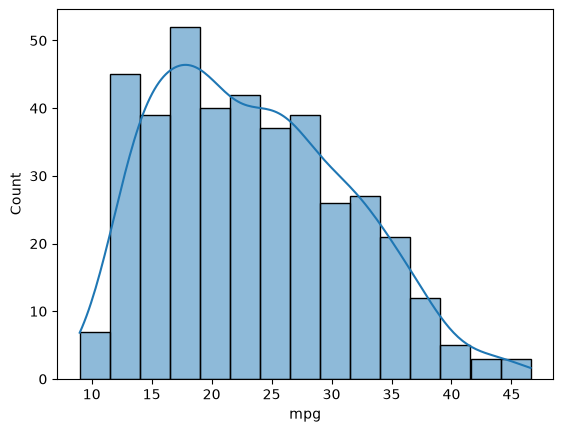

In [10]:
sns.histplot(data=df,x="mpg", bins=15, kde=True)

7. Analiza `weight` con histograma y boxplot. ¿La distribución es simétrica? ¿Hay valores 
extremos según la regla del IQR? Documenta el cálculo. 

<Axes: xlabel='weight', ylabel='Count'>

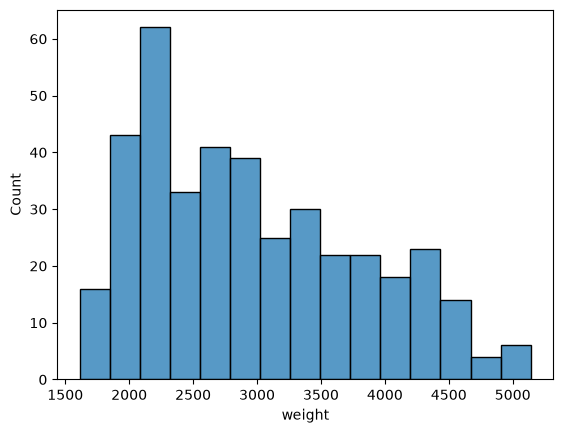

In [11]:
sns.histplot(data=df,x="weight", bins=15)

<Axes: xlabel='weight'>

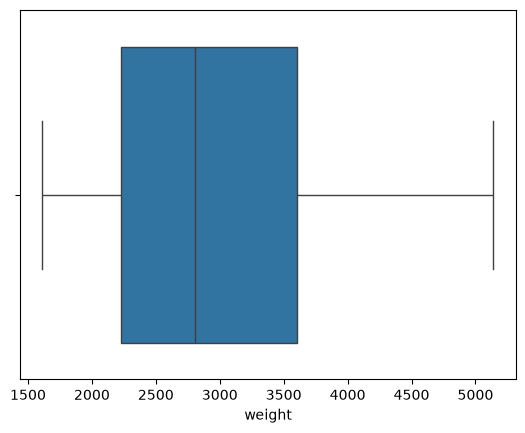

In [12]:
q=df[['weight']].quantile([0.25,0.75]).T
q.columns=['q1','q3']
q['iqr']=q['q3']-q['q1']
q
sns.boxplot(data=df, x='weight')

8. Detecta outliers en `horsepower` usando 1.5·IQR. Lista los vehículos identificados y 
comenta si parecen errores evidentes o automóviles de alta potencia plausibles. 

In [13]:
q= df[["horsepower"]].quantile([0.25,0.75]).T
q.columns=["q1","q3"]
q["iqr"]=q["q3"]-q["q1"]

lower= q["q1"]-1.5*q["iqr"]
print(lower)

upper=q["q3"]+1.5*q["iqr"]
print(upper)

outliers_hp = df[(df['horsepower'] < -1.5) | (df['horsepower'] > 202.5)]
print(outliers_hp[['horsepower']])

horsepower   -1.5
dtype: float64
horsepower    202.5
dtype: float64
     horsepower
6         220.0
7         215.0
8         225.0
13        225.0
25        215.0
27        210.0
67        208.0
94        215.0
95        225.0
116       230.0


9. Explora `cylinders` y `origin` mediante frecuencias y gráficos de barras. ¿Qué categorías 
dominan el dataset? ¿Hay categorías con muy pocos casos?

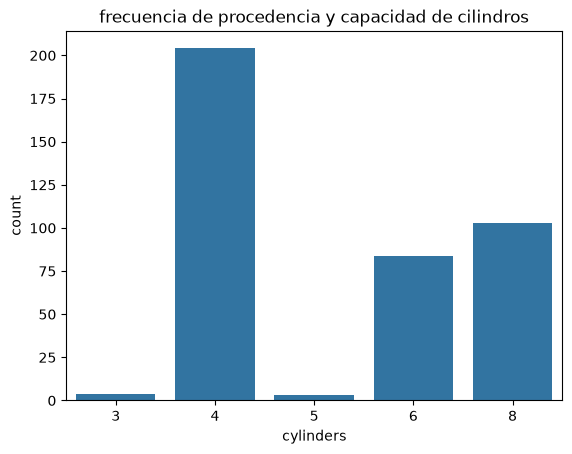

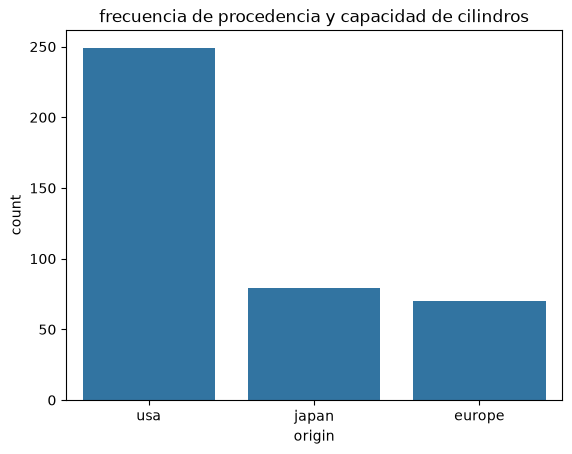

In [14]:
for col in ["cylinders","origin"]:
    sns.countplot(data=df,x=col)
    plt.title(f"frecuencia de procedencia y capacidad de cilindros")
    plt.show()

10. Compara `mpg` entre vehículos con distinto número de cilindros mediante boxplot y 
medias/medianas por grupo. ¿Qué patrón general observas? 

C:\Users\HP\AppData\Local\Temp\ipykernel_12804\2056247594.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


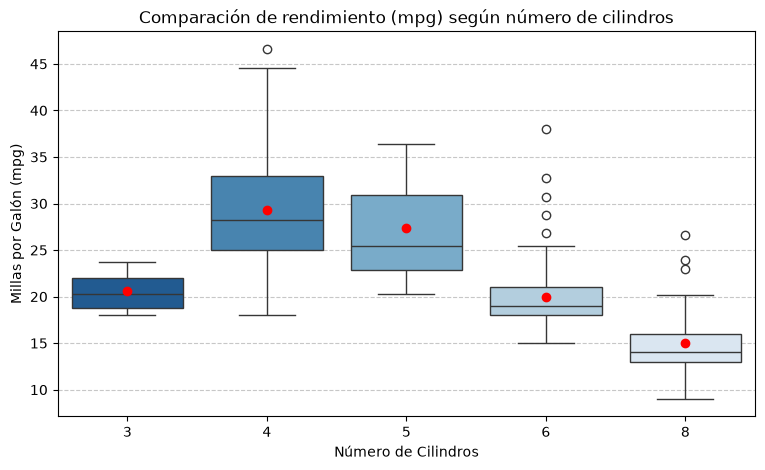

In [15]:

comparacion = (
    df.groupby("cylinders")["mpg"]
    .agg(
        Recuento="count",
        Media="mean",
        Mediana="median",
        Desv_Std="std",
        IQR=lambda x: x.quantile(0.75) - x.quantile(0.25),
    )
    .round(2)
)



plt.figure(figsize=(9, 5))
sns.boxplot(
    data=df,
    x="cylinders",
    y="mpg",
    palette="Blues_r",
    showmeans=True,
    meanprops={
        "marker": "o",
        "markerfacecolor": "red",
        "markeredgecolor": "red",
        "markersize": "6",
    },
)

plt.title(
    "Comparación de rendimiento (mpg) según número de cilindros"
)
plt.xlabel("Número de Cilindros")
plt.ylabel("Millas por Galón (mpg)")
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.show()

11. Compara `mpg` entre los tres orígenes del dataset. Usa boxplot y estadísticas por grupo. 

C:\Users\HP\AppData\Local\Temp\ipykernel_12804\3572351639.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


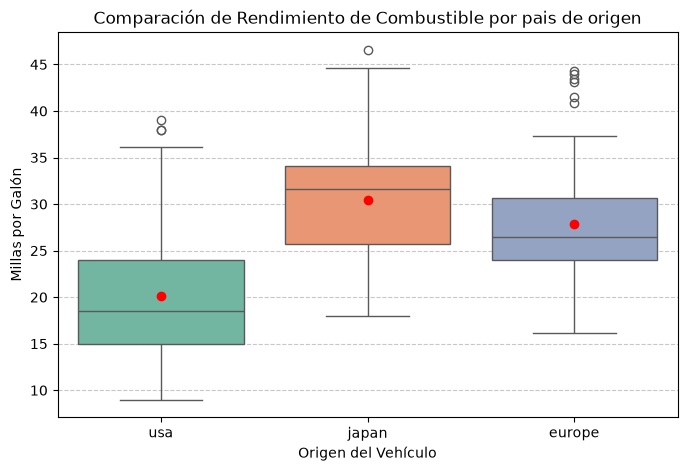

In [16]:
estadis_origen = (
    df.groupby("origin")["mpg"]
    .agg(
        Recuento="count",
        Media="mean",
        Mediana="median",
        Desv_Estd="std",
        Q1=lambda x: x.quantile(0.25),
        Q3=lambda x: x.quantile(0.75),
        IQR=lambda x: x.quantile(0.75) - x.quantile(0.25),
    )
    .round(2)
)

plt.figure(figsize=(8, 5))
sns.boxplot(
    data=df,
    x="origin",
    y="mpg",
    palette="Set2",
    showmeans=True,
    meanprops={
        "marker": "o",
        "markerfacecolor": "red",
        "markeredgecolor": "red",
    },
)

plt.title(
    "Comparación de Rendimiento de Combustible por pais de origen", fontsize=12
)
plt.xlabel("Origen del Vehículo")
plt.ylabel("Millas por Galón")
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.show()

12. Estudia la relación entre `weight` y `mpg` con un scatterplot y la correlación. 

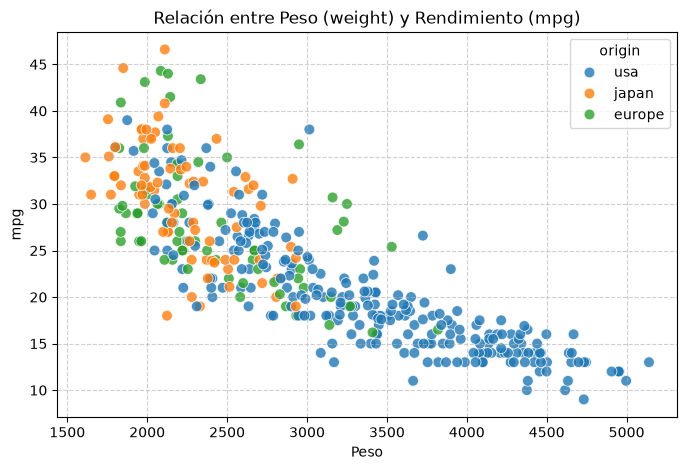

In [17]:
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x="weight",
    y="mpg",
    hue="origin",
    alpha=0.8,
    s=60,
)

plt.title("Relación entre Peso (weight) y Rendimiento (mpg)", fontsize=12)
plt.xlabel("Peso")
plt.ylabel("mpg")
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

13. Estudia la relación entre `horsepower` y `mpg` con scatterplot y correlación. Compara su 
intensidad con la relación `weight`–`mpg`.

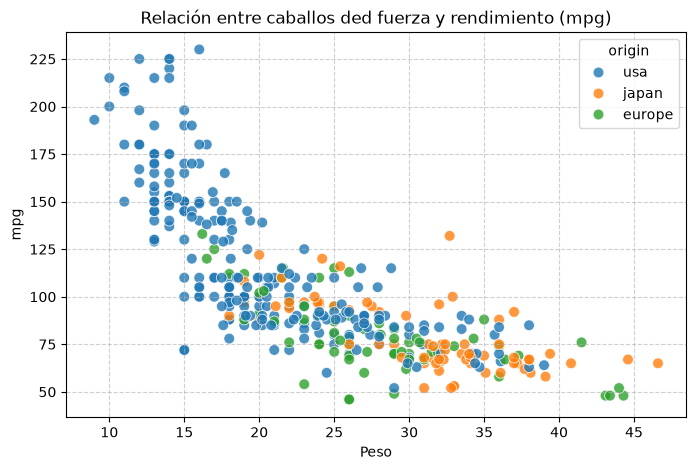

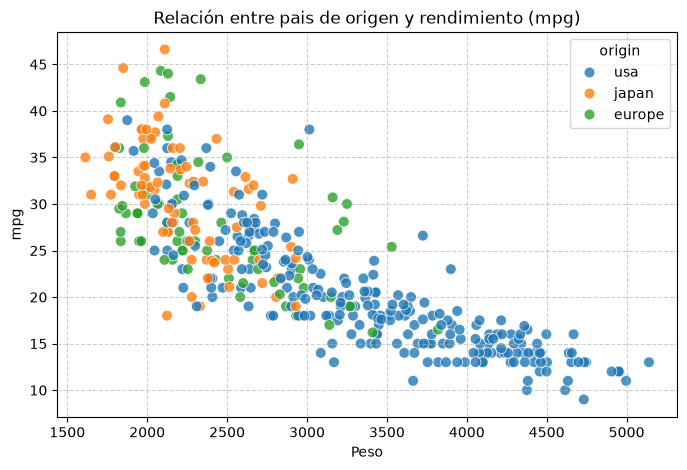

In [18]:
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x='mpg',
    y='horsepower',
    hue="origin",
    alpha=0.8,
    s=60,
)

plt.title("Relación entre caballos ded fuerza y rendimiento (mpg)", fontsize=12)
plt.xlabel("Peso")
plt.ylabel("mpg")
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()
#-----------------------------------
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x='weight',
    y="mpg",
    hue="origin",
    alpha=0.8,
    s=60,
)

plt.title("Relación entre pais de origen y rendimiento (mpg)", fontsize=12)
plt.xlabel("Peso")
plt.ylabel("mpg")
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

14. Construye una matriz de correlación y heatmap de las variables numéricas. Identifica las 
tres variables con mayor asociación lineal absoluta con `mpg` y comenta posibles 
redundancias entre predictores. 

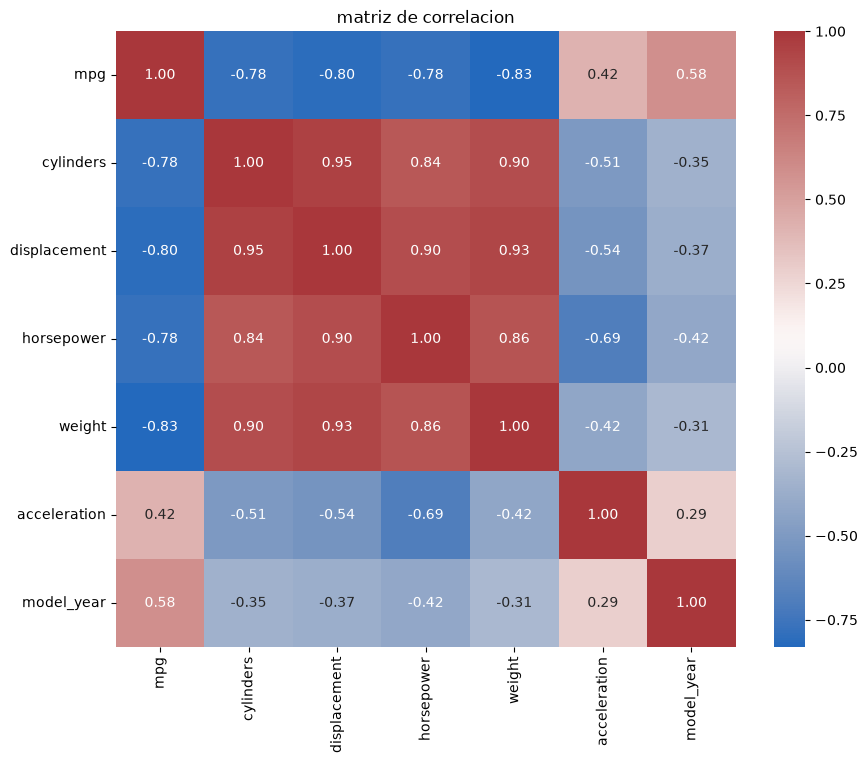

In [19]:
columns_numericas = df.select_dtypes(include="number")
corr = columns_numericas.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag")
plt.title("matriz de correlacion")
plt.show()

15. Realiza un análisis multivariado de `weight` frente a `mpg` incorporando `origin` y 
`cylinders` (mediante color, estilo, facetas u otra codificación). Añade la evolución media de 
`mpg` por `model_year`. 

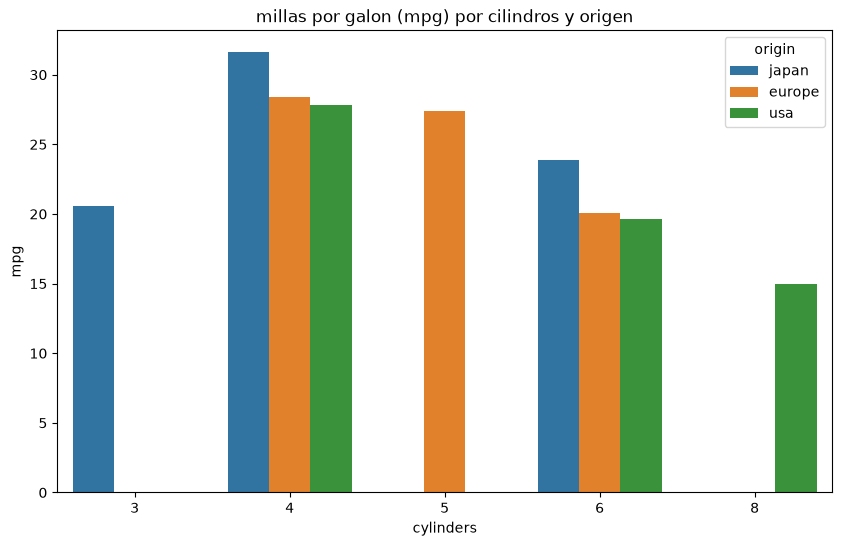

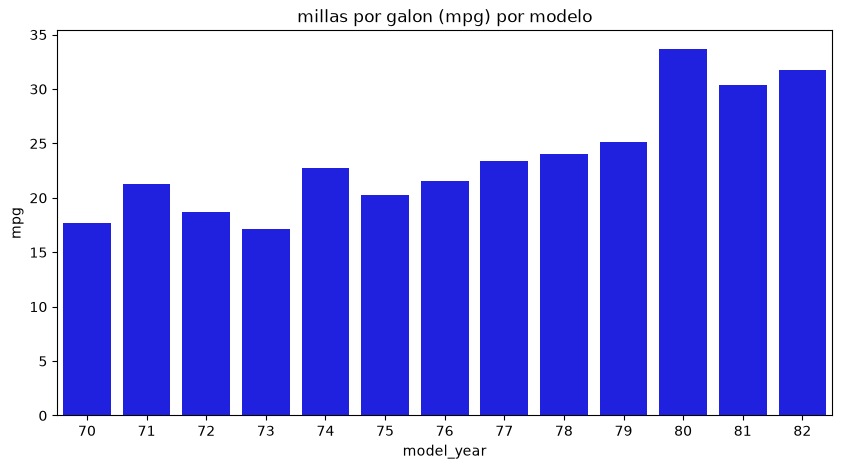

In [20]:
plt.figure(figsize=(10, 6))
sns.barplot(
    data=df,
    x="cylinders",
    y="mpg",
    hue="origin",
    errorbar=None,
)
plt.title("millas por galon (mpg) por cilindros y origen")
plt.show()

plt.figure(figsize=(10, 5))
sns.barplot(
    data=df,
    x="model_year",
    y="mpg",
    color="blue",
    errorbar=None,
)
plt.title("millas por galon (mpg) por modelo")
plt.show()

16. Analiza la evolución de `mpg` por `model_year`. Calcula media y mediana por año y 
represéntalas en una gráfica de líneas.  

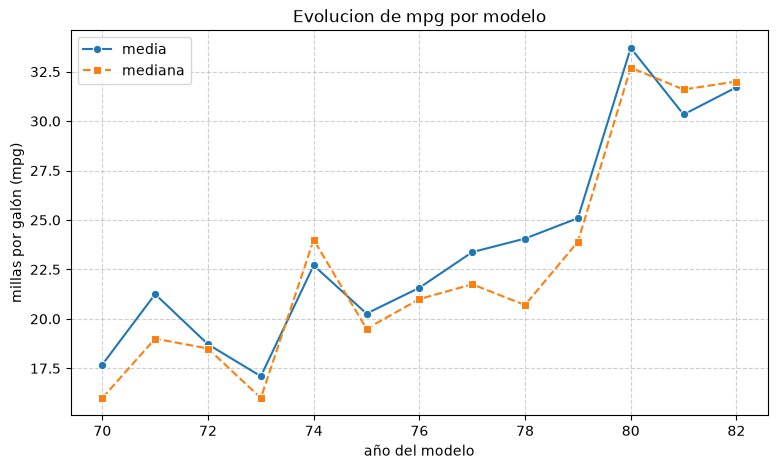

In [21]:
estadisticas_año = df.groupby("model_year")["mpg"].agg(["mean", "median"])


plt.figure(figsize=(9, 5))
sns.lineplot(data=estadisticas_año, x="model_year", y="mean", label="media", marker="o")
sns.lineplot(
    data=estadisticas_año,
    x="model_year",
    y="median",
    label="mediana",
    marker="s",
    linestyle="--",
)

plt.title("Evolucion de mpg por modelo")
plt.xlabel("año del modelo")
plt.ylabel("millas por galón (mpg)")
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

17. Compara el `weight` de los automóviles por `origin` mediante estadísticas y boxplots. 
¿Puede la diferencia de peso ayudar a explicar parte de las diferencias de `mpg` observadas 
entre orígenes? 

               mean  median         std
origin                                 
europe  2423.300000  2240.0  490.043191
japan   2221.227848  2155.0  320.497248
usa     3361.931727  3365.0  794.792506


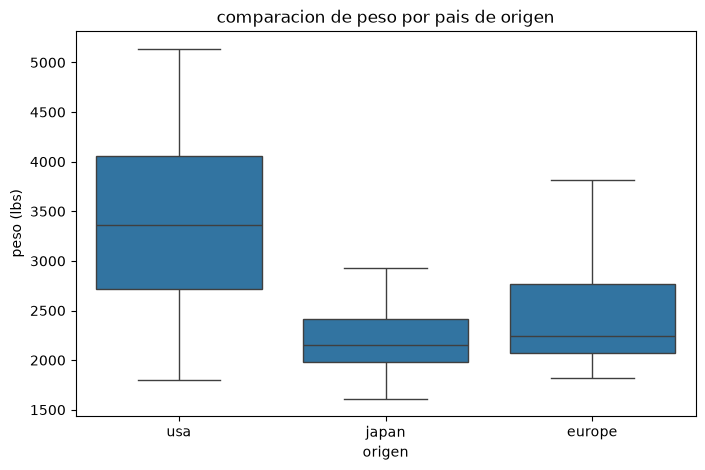

In [22]:
estadisticas = df.groupby("origin")["weight"].agg(["mean", "median", "std"])
print(estadisticas)

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="origin", y="weight")
plt.title("comparacion de peso por pais de origen")
plt.xlabel("origen")
plt.ylabel("peso (lbs)")
plt.show()

18. Estudia el patrón de los valores faltantes de `horsepower`. Compara su frecuencia por 
`origin`, `cylinders` y `model_year`. 

In [23]:
faltantes_hp = df[df["horsepower"].isna()]

print('faltantes por pais de origen')
print(faltantes_hp["origin"].value_counts())
print('=='*100)

print("\n faltantes por cilindros")
print(faltantes_hp["cylinders"].value_counts())
print('=='*100)

print("\n faltantes por modelo")
print(faltantes_hp["model_year"].value_counts())


faltantes por pais de origen
origin
usa       4
europe    2
Name: count, dtype: int64

 faltantes por cilindros
cylinders
4    5
6    1
Name: count, dtype: int64

 faltantes por modelo
model_year
80    2
71    1
74    1
81    1
82    1
Name: count, dtype: int64


19. Analiza la relación entre `acceleration` y `mpg` mediante scatterplot y correlación de 
Pearson. Compara su fuerza con las relaciones de `weight` y `horsepower` con `mpg`. 

Correlación de Pearson con mpg:
acceleration : 0.420
weight       : -0.832
horsepower   : -0.778


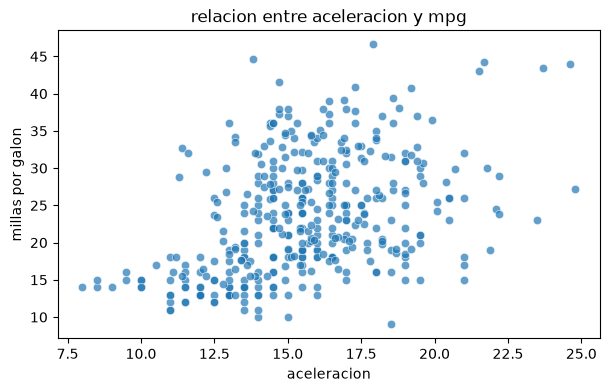

In [25]:
df = sns.load_dataset("mpg")
correlaciones = df[["mpg", "acceleration", "weight", "horsepower"]].corr()["mpg"]

print("Correlación de Pearson con mpg:")
print(f"acceleration : {correlaciones.loc['acceleration']:.3f}")
print(f"weight       : {correlaciones.loc['weight']:.3f}")
print(f"horsepower   : {correlaciones.loc['horsepower']:.3f}")


plt.figure(figsize=(7, 4))
sns.scatterplot(data=df, x="acceleration", y="mpg", alpha=0.7)
plt.title("relacion entre aceleracion y mpg")
plt.xlabel("aceleracion")
plt.ylabel("millas por galon")
plt.show()

20. Explora las relaciones entre `displacement`, `horsepower` y `weight`. Calcula sus 
correlaciones y crea gráficos de dispersión. ¿Qué problema podría aparecer si se usan 
simultáneamente como predictores sin revisar redundancias? 

matriz de correlacion de pearson:
              displacement  horsepower  weight
displacement         1.000       0.897   0.933
horsepower           0.897       1.000   0.865
weight               0.933       0.865   1.000


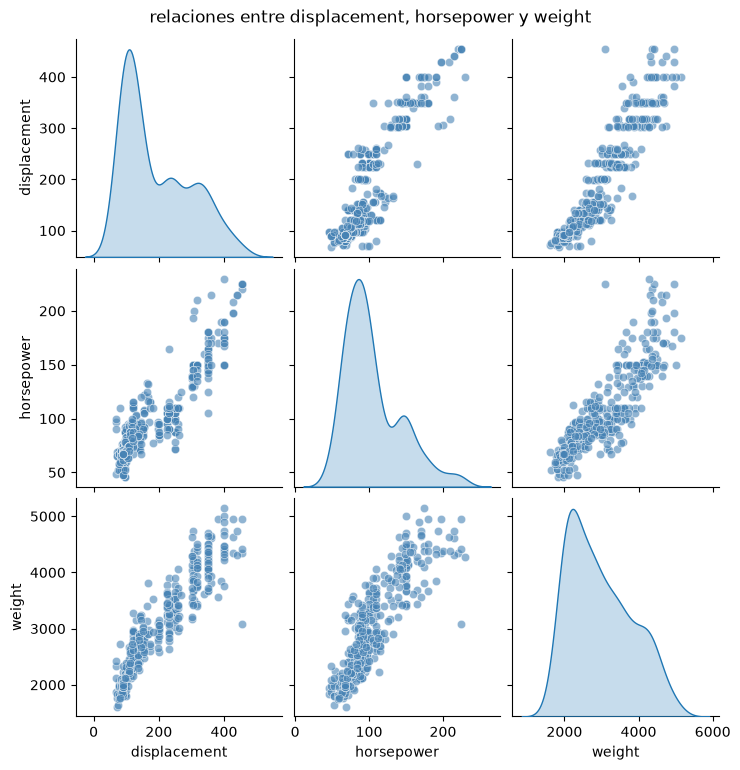

In [26]:
variables = ["displacement", "horsepower", "weight"]
correlacion = df[variables].corr()

print("matriz de correlacion de pearson:")
print(correlacion.round(3))

sns.pairplot(
    data=df[variables],
    kind="scatter",
    diag_kind="kde",
    plot_kws={"alpha": 0.6, "color": "steelblue"},
)
plt.suptitle(
    "relaciones entre displacement, horsepower y weight", y=1.02, fontsize=12
)
plt.show()

21. Construye una tabla pivote con el `mpg` medio por `cylinders` y `origin`, incluyendo el 
número de automóviles por grupo. ¿El patrón de cilindros se mantiene dentro de cada origen? 
Señala grupos con muestras pequeñas. 

In [27]:
tabla_pivote = df.pivot_table(
    index="cylinders",
    columns="origin",
    values="mpg",
    aggfunc=["mean", "count"],
).round(2)

print(tabla_pivote)

            mean                count             
origin    europe  japan    usa europe japan    usa
cylinders                                         
3            NaN  20.55    NaN    NaN   4.0    NaN
4          28.41  31.60  27.84   63.0  69.0   72.0
5          27.37    NaN    NaN    3.0   NaN    NaN
6          20.10  23.88  19.66    4.0   6.0   74.0
8            NaN    NaN  14.96    NaN   NaN  103.0


22. Compara la evolución temporal de `mpg` entre `origin` usando líneas por grupo. ¿Los tres 
orígenes mejoran con el tiempo? ¿La brecha entre orígenes permanece constante? 

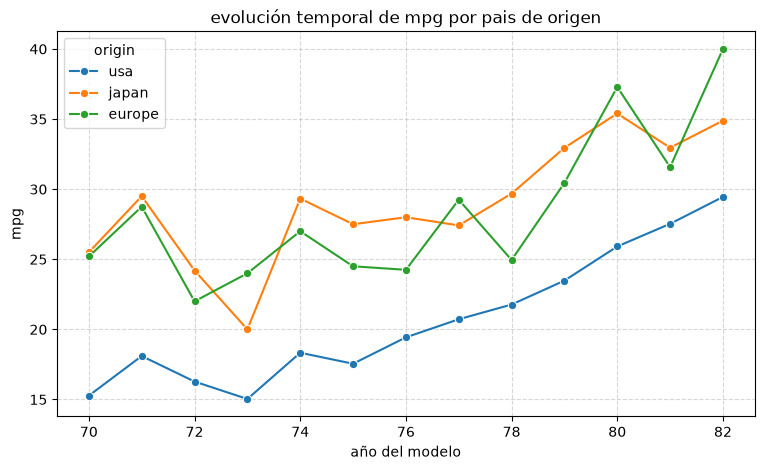

In [28]:
plt.figure(figsize=(9, 5))
sns.lineplot(
    data=df,
    x="model_year",
    y="mpg",
    hue="origin",
    marker="o",
    errorbar=None,
)

plt.title("evolución temporal de mpg por pais de origen")
plt.xlabel("año del modelo")
plt.ylabel("mpg")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

23. Compara los outliers de `horsepower` detectados mediante 1.5·IQR y mediante |z| > 3. 
Lista los vehículos más extremos y explica por qué un método puede ser más estricto que el 
otro en una distribución asimétrica. 

In [29]:
datos = df.dropna(subset=["horsepower"]).copy()
hp = datos["horsepower"]

Q1 = hp.quantile(0.25)
Q3 = hp.quantile(0.75)
IQR = Q3 - Q1
limite_superior_iqr = Q3 + 1.5 * IQR
outliers_iqr = datos[hp > limite_superior_iqr]

mean_hp = hp.mean()
std_hp = hp.std()
z_scores = (hp - mean_hp) / std_hp
outliers_z = datos[abs(z_scores) > 3]

print(f"limite superior IQR: {limite_superior_iqr:.2f} HP")
print(f"outliers por IQR: {len(outliers_iqr)} vehículos")
print(f"outliers por z-score (|z| > 3): {len(outliers_z)} vehículos")

print("\nVehículos más extremos (Potencia > 220 HP):")
print(
    datos[hp >= 220][["name", "horsepower", "weight", "model_year", "origin"]]
)

limite superior IQR: 202.50 HP
outliers por IQR: 10 vehículos
outliers por z-score (|z| > 3): 5 vehículos

Vehículos más extremos (Potencia > 220 HP):
                         name  horsepower  weight  model_year origin
6            chevrolet impala       220.0    4354          70    usa
8            pontiac catalina       225.0    4425          70    usa
13    buick estate wagon (sw)       225.0    3086          70    usa
95   buick electra 225 custom       225.0    4951          73    usa
116        pontiac grand prix       230.0    4278          73    usa


24. Construye un `pairplot` con `mpg`, `weight`, `horsepower`, `displacement` y 
`model_year`, usando `origin` como color. 

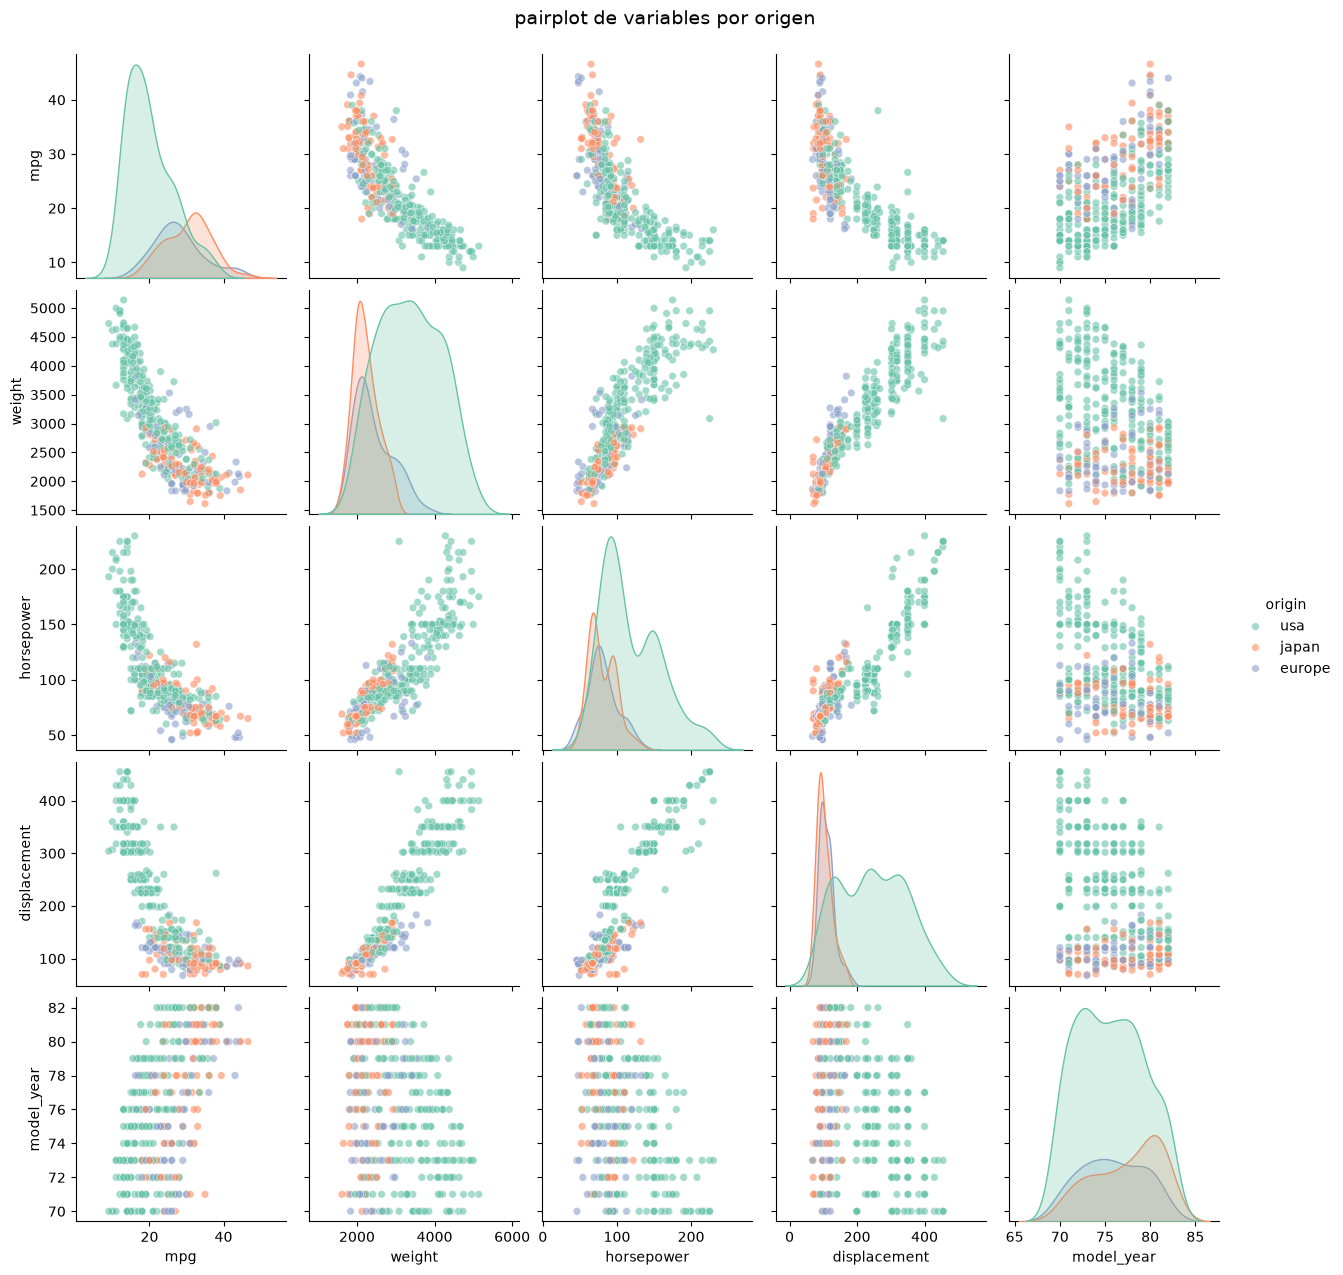

In [30]:
variables = ["mpg", "weight", "horsepower", "displacement", "model_year"]

sns.pairplot(
    data=df,
    vars=variables,
    hue="origin",
    palette="Set2",
    diag_kind="kde",
    plot_kws={"alpha": 0.6, "s": 30},
)

plt.suptitle(
    "pairplot de variables por origen", y=1.02, fontsize=14
)
plt.show()

25. Elabora un “registro de decisiones” para preparar un análisis posterior: decide qué harías 
con los nulos de `horsepower`, `name`, `origin`, los outliers de potencia y las variables 
altamente correlacionadas. 

In [ ]:
# Se sugiere imputar los valores faltantes en horsepower mediante la mediana y los de origin utilizando la moda.
# En el caso de name, se plantea asignar la etiqueta "Unknown" a los nulos o valorar la eliminación de la columna por actuar como identificador único.
# Se recomienda examinar detenidamente los valores atípicos en horsepower antes de optar por descartarlos.
# Por último, se aconseja evaluar la alta correlación entre variables para conservar solo una representativa y evitar redundancia.